In [53]:
import pandas as pd

df = pd.read_csv("Agriculture_price_dataset.csv")

print(df.shape)
print(df.columns)
print(df.head())
print(df.info())

(737392, 10)
Index(['STATE', 'District Name', 'Market Name', 'Commodity', 'Variety',
       'Grade', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price Date'],
      dtype='object')
           STATE District Name        Market Name Commodity           Variety  \
0    Maharashtra        nashik  Lasalgaon(Niphad)     Wheat  Maharashtra 2189   
1    Maharashtra        satara              Patan    Tomato             Other   
2  Uttar Pradesh      mainpuri              Bewar    Potato             Local   
3      Rajasthan   chittorgarh          Nimbahera     Wheat             Other   
4      Rajasthan    pratapgarh         Pratapgarh     Onion             Other   

  Grade  Min_Price  Max_Price  Modal_Price Price Date  
0   FAQ     2172.0     2399.0       2300.0   6/6/2023  
1   FAQ     1000.0     1500.0       1250.0   6/6/2023  
2   FAQ      800.0      820.0        810.0   6/6/2023  
3   FAQ     2040.0     2668.0       2300.0   6/6/2023  
4   FAQ      476.0     1043.0        617.0   6/6/2023 

In [54]:
# Filter Wheat records
wheat_df = df[df["Commodity"].str.lower() == "wheat"].copy()

print("Wheat records:", len(wheat_df))

print("\nStates:")
print(wheat_df["STATE"].nunique())
print(wheat_df["STATE"].value_counts().head(15))

print("\nMarkets:")
print("Unique markets:", wheat_df["Market Name"].nunique())

print("\nDate range:")
print(wheat_df["Price Date"].min(), "to", wheat_df["Price Date"].max())

print("\nWheat varieties:")
print(wheat_df["Variety"].value_counts().head(20))

Wheat records: 76976

States:
18
STATE
Madhya Pradesh      26657
Uttar Pradesh       19983
Maharashtra          9084
Rajasthan            8447
Gujarat              7063
West Bengal          2266
Karnataka            1082
Himachal Pradesh      764
Assam                 459
Delhi                 424
Chattisgarh           358
Chhattisgarh          181
Bihar                 170
Andhra Pradesh         22
Haryana                 7
Name: count, dtype: int64

Markets:
Unique markets: 738

Date range:
1/1/2024 to 9/9/2023

Wheat varieties:
Variety
Other                   27686
Dara                    20539
Mill Quality             6138
Lokwan                   4434
147 Average              2866
Local                    2284
Deshi                    1565
Maharashtra 2189         1382
Sharbati                 1288
Sonalika                 1126
Kalyan                    992
Lok-1                     668
Medium                    647
Dara Mill Quality         545
Hybrid                    526
Lok -

In [55]:
# Convert Price Date to datetime
wheat_df["Price Date"] = pd.to_datetime(
    wheat_df["Price Date"],
    dayfirst=False,
    errors="coerce"
)

# Check date range properly
print("Date range:")
print(wheat_df["Price Date"].min())
print(wheat_df["Price Date"].max())

print("\nMissing dates:")
print(wheat_df["Price Date"].isna().sum())

# Number of observations per market
market_counts = (
    wheat_df.groupby(["STATE", "Market Name"])
    .size()
    .sort_values(ascending=False)
)

print("\nTop 20 markets by number of records:")
print(market_counts.head(20))

Date range:
2023-06-06 00:00:00
2024-02-06 00:00:00

Missing dates:
0

Top 20 markets by number of records:
STATE           Market Name    
Madhya Pradesh  Kalapipal          582
West Bengal     Durgapur           478
Uttar Pradesh   Pratapgarh         392
Rajasthan       Pratapgarh         392
Gujarat         Dahod              376
                Rajkot             362
                Savarkundla        344
                Amreli             342
Maharashtra     Nagpur             316
Gujarat         Jasdan             315
Madhya Pradesh  Jatara             311
                Kasrawad           309
Gujarat         Gondal             294
                Porbandar          281
Maharashtra     Amarawati          279
Madhya Pradesh  Bhopal             272
                Bina               261
Karnataka       Basava Kalayana    259
Delhi           Najafgarh          256
Madhya Pradesh  Badnagar           253
dtype: int64


In [56]:
# Select Kalapipal, Madhya Pradesh
kalapipal = wheat_df[
    (wheat_df["STATE"] == "Madhya Pradesh") &
    (wheat_df["Market Name"] == "Kalapipal")
].copy()

# Sort chronologically
kalapipal = kalapipal.sort_values("Price Date")

print("Records:", len(kalapipal))
print("Start:", kalapipal["Price Date"].min())
print("End:", kalapipal["Price Date"].max())

# Check duplicate dates
print("\nDuplicate dates:")
print(kalapipal["Price Date"].duplicated().sum())

# Calculate gaps between observations
date_gaps = kalapipal["Price Date"].diff().dt.days.dropna()

print("\nGap statistics:")
print(date_gaps.describe())

print("\nLargest gaps:")
print(date_gaps.sort_values(ascending=False).head(20))

Records: 582
Start: 2023-06-06 00:00:00
End: 2023-12-20 00:00:00

Duplicate dates:
388

Gap statistics:
count    581.000000
mean       0.339071
std        0.488141
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        2.000000
Name: Price Date, dtype: float64

Largest gaps:
42072     2.0
163344    2.0
240429    2.0
197643    2.0
244729    1.0
6177      1.0
3986      1.0
9432      1.0
11147     1.0
15950     1.0
13942     1.0
250705    1.0
236855    1.0
235186    1.0
238429    1.0
19570     1.0
8577      1.0
230925    1.0
229764    1.0
228658    1.0
Name: Price Date, dtype: float64


In [57]:
# Aggregate multiple Wheat records on the same day
daily_price = (
    kalapipal
    .groupby("Price Date", as_index=False)
    .agg({
        "Modal_Price": "mean",
        "Min_Price": "mean",
        "Max_Price": "mean"
    })
)

# Sort by date
daily_price = daily_price.sort_values("Price Date").reset_index(drop=True)

print("Original records:", len(kalapipal))
print("Daily records:", len(daily_price))

print("\nDate range:")
print(daily_price["Price Date"].min())
print(daily_price["Price Date"].max())

print("\nFirst 10 days:")
display(daily_price.head(10))

Original records: 582
Daily records: 194

Date range:
2023-06-06 00:00:00
2023-12-20 00:00:00

First 10 days:


,Price Date,Modal_Price,Min_Price,Max_Price
0,2023-06-06,2225.000000,2000.000000,2495.333333
1,2023-06-07,2276.666667,2073.333333,2563.333333
2,2023-06-08,2398.333333,2140.000000,2635.000000
3,2023-06-09,2356.666667,2141.666667,2538.333333
4,2023-06-10,2341.666667,2128.333333,2551.666667
5,2023-06-11,2370.000000,2133.333333,2515.000000
6,2023-06-12,2378.333333,2171.666667,2580.333333
7,2023-06-13,2315.333333,2157.666667,2487.000000
8,2023-06-14,2261.666667,2070.333333,2510.333333
9,2023-06-15,2343.333333,2160.000000,2482.000000


In [58]:
# Check whether there are still duplicate dates
print("Duplicate dates:",
      daily_price["Price Date"].duplicated().sum())

# Check missing dates
all_dates = pd.date_range(
    daily_price["Price Date"].min(),
    daily_price["Price Date"].max(),
    freq="D"
)

missing_dates = all_dates.difference(daily_price["Price Date"])

print("Expected calendar days:", len(all_dates))
print("Missing calendar days:", len(missing_dates))

print("\nMissing dates:")
print(missing_dates)


Duplicate dates: 0
Expected calendar days: 198
Missing calendar days: 4

Missing dates:
DatetimeIndex(['2023-06-30', '2023-10-02', '2023-10-31', '2023-12-10'], dtype='datetime64[ns]', freq=None)


In [59]:
# Create complete daily date range
full_dates = pd.date_range(
    daily_price["Price Date"].min(),
    daily_price["Price Date"].max(),
    freq="D"
)

# Reindex to include missing dates
daily_price = (
    daily_price
    .set_index("Price Date")
    .reindex(full_dates)
)

daily_price.index.name = "Price Date"

# Interpolate missing prices based on neighboring dates
daily_price["Modal_Price"] = daily_price["Modal_Price"].interpolate(
    method="time"
)

daily_price["Min_Price"] = daily_price["Min_Price"].interpolate(
    method="time"
)

daily_price["Max_Price"] = daily_price["Max_Price"].interpolate(
    method="time"
)

# Reset index
daily_price = daily_price.reset_index()

print("Rows after filling:", len(daily_price))
print("Remaining missing values:")
print(daily_price.isna().sum())

Rows after filling: 198
Remaining missing values:
Price Date     0
Modal_Price    0
Min_Price      0
Max_Price      0
dtype: int64


In [60]:
missing_dates = pd.to_datetime([
    "2023-06-30",
    "2023-10-02",
    "2023-10-31",
    "2023-12-10"
])

display(
    daily_price[
        daily_price["Price Date"].isin(missing_dates)
    ]
)

,Price Date,Modal_Price,Min_Price,Max_Price
24,2023-06-30,2352.500000,2128.333333,2528.333333
118,2023-10-02,2330.833333,2178.333333,2501.833333
147,2023-10-31,2390.833333,2163.333333,2599.666667
187,2023-12-10,2316.666667,2151.666667,2475.833333


In [61]:
# Make a copy
model_df = daily_price.copy()

# Target = next day's modal price
model_df["target_price"] = model_df["Modal_Price"].shift(-1)

# Lag features
model_df["lag_1"] = model_df["Modal_Price"].shift(1)
model_df["lag_3"] = model_df["Modal_Price"].shift(3)
model_df["lag_7"] = model_df["Modal_Price"].shift(7)
model_df["lag_14"] = model_df["Modal_Price"].shift(14)
model_df["lag_30"] = model_df["Modal_Price"].shift(30)

# Rolling price features
model_df["rolling_mean_7"] = (
    model_df["Modal_Price"]
    .rolling(window=7)
    .mean()
)

model_df["rolling_mean_14"] = (
    model_df["Modal_Price"]
    .rolling(window=14)
    .mean()
)

model_df["rolling_mean_30"] = (
    model_df["Modal_Price"]
    .rolling(window=30)
    .mean()
)

# Rolling volatility
model_df["rolling_std_7"] = (
    model_df["Modal_Price"]
    .rolling(window=7)
    .std()
)

# Calendar features
model_df["day_of_week"] = model_df["Price Date"].dt.dayofweek
model_df["month"] = model_df["Price Date"].dt.month

print(model_df.head(35))
print("\nShape:", model_df.shape)
print("\nMissing values:")
print(model_df.isna().sum())

   Price Date  Modal_Price    Min_Price    Max_Price  target_price  \
0  2023-06-06  2225.000000  2000.000000  2495.333333   2276.666667   
1  2023-06-07  2276.666667  2073.333333  2563.333333   2398.333333   
2  2023-06-08  2398.333333  2140.000000  2635.000000   2356.666667   
3  2023-06-09  2356.666667  2141.666667  2538.333333   2341.666667   
4  2023-06-10  2341.666667  2128.333333  2551.666667   2370.000000   
5  2023-06-11  2370.000000  2133.333333  2515.000000   2378.333333   
6  2023-06-12  2378.333333  2171.666667  2580.333333   2315.333333   
7  2023-06-13  2315.333333  2157.666667  2487.000000   2261.666667   
8  2023-06-14  2261.666667  2070.333333  2510.333333   2343.333333   
9  2023-06-15  2343.333333  2160.000000  2482.000000   2253.333333   
10 2023-06-16  2253.333333  2063.333333  2496.666667   2335.000000   
11 2023-06-17  2335.000000  2168.000000  2510.333333   2408.333333   
12 2023-06-18  2408.333333  2113.333333  2523.333333   2181.666667   
13 2023-06-19  2181.

In [62]:
# Remove rows where features/target are not available
model_df = model_df.dropna().reset_index(drop=True)

print("Clean modeling dataset shape:", model_df.shape)

print("\nDate range:")
print(model_df["Price Date"].min())
print(model_df["Price Date"].max())

print("\nRemaining missing values:")
print(model_df.isna().sum())


Clean modeling dataset shape: (167, 16)

Date range:
2023-07-06 00:00:00
2023-12-19 00:00:00

Remaining missing values:
Price Date         0
Modal_Price        0
Min_Price          0
Max_Price          0
target_price       0
lag_1              0
lag_3              0
lag_7              0
lag_14             0
lag_30             0
rolling_mean_7     0
rolling_mean_14    0
rolling_mean_30    0
rolling_std_7      0
day_of_week        0
month              0
dtype: int64


In [63]:
# Define features
features = [
    "lag_1",
    "lag_3",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30",
    "rolling_std_7",
    "day_of_week",
    "month"
]

target = "target_price"

# Chronological 80/20 split
split_index = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining period:")
print(train_df["Price Date"].min(), "→", train_df["Price Date"].max())

print("\nTesting period:")
print(test_df["Price Date"].min(), "→", test_df["Price Date"].max())

Training samples: 133
Testing samples: 34

Training period:
2023-07-06 00:00:00 → 2023-11-15 00:00:00

Testing period:
2023-11-16 00:00:00 → 2023-12-19 00:00:00


In [64]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Naive baseline:
# Tomorrow's price = today's price
baseline_predictions = X_test["lag_1"]

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

baseline_mape = np.mean(
    np.abs((y_test - baseline_predictions) / y_test)
) * 100

print("BASELINE RESULTS")
print("----------------")
print(f"MAE  : {baseline_mae:.2f}")
print(f"RMSE : {baseline_rmse:.2f}")
print(f"MAPE : {baseline_mape:.2f}%")

BASELINE RESULTS
----------------
MAE  : 63.69
RMSE : 78.55
MAPE : 2.71%


In [65]:
!pip install lightgbm -q

In [66]:
from lightgbm import LGBMRegressor

model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    num_leaves=15,
    random_state=42,
    verbosity=-1
)

model.fit(
    X_train,
    y_train
)

predictions = model.predict(X_test)

print("First 10 predictions:")
print(predictions[:10])

First 10 predictions:
[2375.43845677 2389.10972487 2366.61988053 2379.97357234 2348.62686943
 2325.50919714 2341.9369272  2307.77349463 2322.56232432 2325.7783319 ]


In [67]:
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

mape = np.mean(
    np.abs((y_test - predictions) / y_test)
) * 100

print("LIGHTGBM RESULTS")
print("----------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")

LIGHTGBM RESULTS
----------------
MAE  : 44.91
RMSE : 57.15
MAPE : 1.90%


In [68]:
print("MODEL COMPARISON")
print("================")

print(f"Baseline MAE : {baseline_mae:.2f}")
print(f"LightGBM MAE : {mae:.2f}")

print()

print(f"Baseline RMSE : {baseline_rmse:.2f}")
print(f"LightGBM RMSE : {rmse:.2f}")

print()

print(f"Baseline MAPE : {baseline_mape:.2f}%")
print(f"LightGBM MAPE : {mape:.2f}%")

MODEL COMPARISON
Baseline MAE : 63.69
LightGBM MAE : 44.91

Baseline RMSE : 78.55
LightGBM RMSE : 57.15

Baseline MAPE : 2.71%
LightGBM MAPE : 1.90%


In [69]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)

            Feature  Importance
8     rolling_std_7         113
1             lag_3         108
0             lag_1          95
7   rolling_mean_30          89
3            lag_14          68
4            lag_30          63
2             lag_7          51
6   rolling_mean_14          51
5    rolling_mean_7          43
10            month          35
9       day_of_week          24


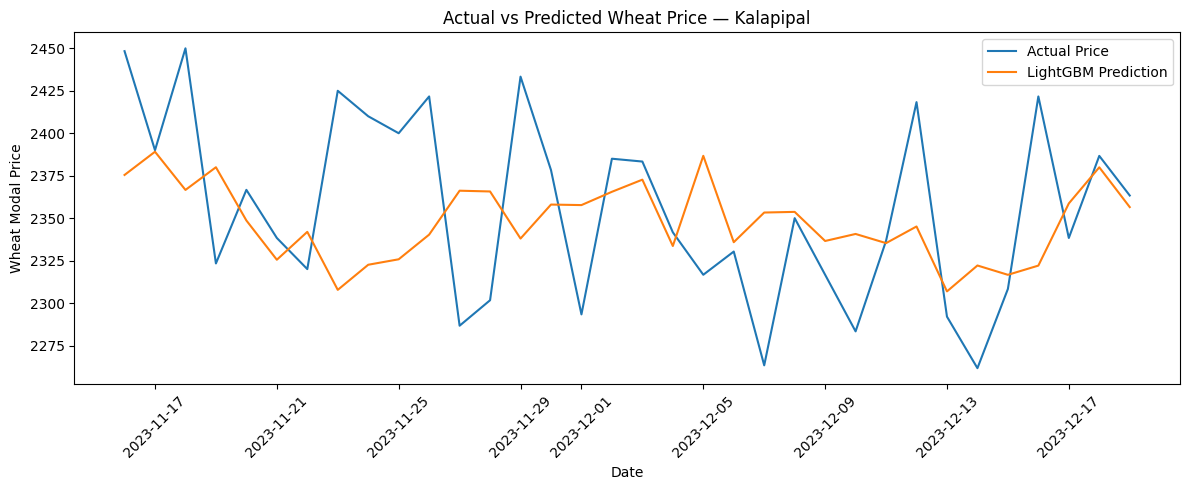

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    test_df["Price Date"],
    y_test.values,
    label="Actual Price"
)

plt.plot(
    test_df["Price Date"],
    predictions,
    label="LightGBM Prediction"
)

plt.xlabel("Date")
plt.ylabel("Wheat Modal Price")
plt.title("Actual vs Predicted Wheat Price — Kalapipal")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [71]:
# Create prediction results table
results = test_df[["Price Date"]].copy()

results["Actual"] = y_test.values
results["Predicted"] = predictions

results["Error"] = results["Actual"] - results["Predicted"]
results["Absolute_Error"] = abs(results["Error"])
results["Percentage_Error"] = (
    results["Absolute_Error"] / results["Actual"]
) * 100

display(results.head(10))

print("Average Absolute Error:",
      results["Absolute_Error"].mean())

print("Maximum Absolute Error:",
      results["Absolute_Error"].max())

print("Average Percentage Error:",
      results["Percentage_Error"].mean())

,Price Date,Actual,Predicted,Error,Absolute_Error,Percentage_Error
133,2023-11-16,2448.333333,2375.438457,72.894877,72.894877,2.977326
134,2023-11-17,2390.000000,2389.109725,0.890275,0.890275,0.037250
135,2023-11-18,2450.000000,2366.619881,83.380119,83.380119,3.403270
136,2023-11-19,2323.333333,2379.973572,-56.640239,56.640239,2.437887
137,2023-11-20,2366.666667,2348.626869,18.039797,18.039797,0.762245
138,2023-11-21,2338.333333,2325.509197,12.824136,12.824136,0.548431
139,2023-11-22,2320.000000,2341.936927,-21.936927,21.936927,0.945557
140,2023-11-23,2425.000000,2307.773495,117.226505,117.226505,4.834083
141,2023-11-24,2410.000000,2322.562324,87.437676,87.437676,3.628119
142,2023-11-25,2400.000000,2325.778332,74.221668,74.221668,3.092570


Average Absolute Error: 44.90757868241036
Maximum Absolute Error: 117.22650537480013
Average Percentage Error: 1.898808106138891


In [72]:
models = {
    "LightGBM_1": LGBMRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        num_leaves=15,
        random_state=42,
        verbosity=-1
    ),

    "LightGBM_2": LGBMRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=4,
        num_leaves=20,
        random_state=42,
        verbosity=-1
    ),

    "LightGBM_3": LGBMRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=5,
        num_leaves=25,
        random_state=42,
        verbosity=-1
    )
}

model_results = []

for name, m in models.items():

    m.fit(X_train, y_train)

    pred = m.predict(X_test)

    model_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAPE": np.mean(
            np.abs((y_test - pred) / y_test)
        ) * 100
    })

comparison_df = pd.DataFrame(model_results)

display(comparison_df)

,Model,MAE,RMSE,MAPE
0,LightGBM_1,45.250313,56.760818,1.913832
1,LightGBM_2,44.240792,56.198622,1.871703
2,LightGBM_3,44.194283,56.504495,1.868249


In [73]:
# Count unique dates for each Wheat mandi
market_stats = (
    wheat_df.groupby(["STATE", "Market Name"])
    .agg(
        records=("Price Date", "count"),
        unique_dates=("Price Date", "nunique"),
        start_date=("Price Date", "min"),
        end_date=("Price Date", "max")
    )
    .reset_index()
)

# Keep markets with at least 100 unique days
good_markets = market_stats[
    market_stats["unique_dates"] >= 100
].sort_values(
    "unique_dates",
    ascending=False
)

print("Markets with >=100 unique dates:",
      len(good_markets))

display(good_markets.head(30))

Markets with >=100 unique dates: 386


,STATE,Market Name,records,unique_dates,start_date,end_date
735,West Bengal,Bishnupur(Bankura),244,244,2023-06-06,2024-02-06
737,West Bengal,Durgapur,478,239,2023-06-06,2024-02-06
651,Uttar Pradesh,Jafarganj,238,238,2023-06-06,2024-02-06
733,West Bengal,Asansol,238,238,2023-06-06,2024-02-06
738,West Bengal,Kandi,236,236,2023-06-06,2024-02-06
720,Uttar Pradesh,Sultanpur,235,235,2023-06-06,2024-02-06
569,Rajasthan,Pratapgarh,392,231,2023-06-06,2024-02-06
693,Uttar Pradesh,Pratapgarh,392,231,2023-06-06,2024-02-06
726,Uttar Pradesh,Unnao,227,227,2023-06-06,2024-02-06
723,Uttar Pradesh,Tulsipur,225,225,2023-06-06,2024-02-06


In [74]:
# Select top 10 markets by unique dates
selected_markets = good_markets.head(10).copy()

print("Selected markets:")
display(
    selected_markets[
        ["STATE", "Market Name", "records",
         "unique_dates", "start_date", "end_date"]
    ]
)

Selected markets:


,STATE,Market Name,records,unique_dates,start_date,end_date
735,West Bengal,Bishnupur(Bankura),244,244,2023-06-06,2024-02-06
737,West Bengal,Durgapur,478,239,2023-06-06,2024-02-06
651,Uttar Pradesh,Jafarganj,238,238,2023-06-06,2024-02-06
733,West Bengal,Asansol,238,238,2023-06-06,2024-02-06
738,West Bengal,Kandi,236,236,2023-06-06,2024-02-06
720,Uttar Pradesh,Sultanpur,235,235,2023-06-06,2024-02-06
569,Rajasthan,Pratapgarh,392,231,2023-06-06,2024-02-06
693,Uttar Pradesh,Pratapgarh,392,231,2023-06-06,2024-02-06
726,Uttar Pradesh,Unnao,227,227,2023-06-06,2024-02-06
723,Uttar Pradesh,Tulsipur,225,225,2023-06-06,2024-02-06


In [75]:
# ============================================
# CREATE CLEAN MULTI-MANDI DATASET
# ============================================

selected_data = []

for _, row in selected_markets.iterrows():

    state = row["STATE"]
    market = row["Market Name"]

    temp = wheat_df[
        (wheat_df["STATE"] == state) &
        (wheat_df["Market Name"] == market)
    ].copy()

    # Convert date just in case
    temp["Price Date"] = pd.to_datetime(
        temp["Price Date"],
        errors="coerce"
    )

    # Multiple wheat records can exist on the same date
    # Aggregate them into one daily price
    temp = (
        temp.groupby("Price Date", as_index=False)
        .agg({
            "Modal_Price": "mean",
            "Min_Price": "mean",
            "Max_Price": "mean"
        })
    )

    # Keep market identity
    temp["STATE"] = state
    temp["Market Name"] = market

    selected_data.append(temp)

# Combine all selected markets
multi_mandi_df = pd.concat(
    selected_data,
    ignore_index=True
)

# Sort correctly
multi_mandi_df = multi_mandi_df.sort_values(
    ["STATE", "Market Name", "Price Date"]
).reset_index(drop=True)

print("Total rows:", len(multi_mandi_df))
print("Unique markets:",
      multi_mandi_df[["STATE", "Market Name"]].drop_duplicates().shape[0])

display(multi_mandi_df.head(20))

Total rows: 2344
Unique markets: 10


,Price Date,Modal_Price,Min_Price,Max_Price,STATE,Market Name
0,2023-06-06,2295.0,2228.5,2495.5,Rajasthan,Pratapgarh
1,2023-06-07,2296.5,2223.5,2516.0,Rajasthan,Pratapgarh
2,2023-06-08,2288.0,2225.0,2522.0,Rajasthan,Pratapgarh
3,2023-06-09,2350.0,2300.0,2450.0,Rajasthan,Pratapgarh
4,2023-06-10,2360.0,2300.0,2400.0,Rajasthan,Pratapgarh
5,2023-06-11,2340.0,2300.0,2500.0,Rajasthan,Pratapgarh
6,2023-06-12,2294.5,2225.0,2488.0,Rajasthan,Pratapgarh
7,2023-06-13,2256.5,2199.0,2425.0,Rajasthan,Pratapgarh
8,2023-06-14,2247.5,2180.5,2445.0,Rajasthan,Pratapgarh
9,2023-06-15,2312.5,2225.0,2530.0,Rajasthan,Pratapgarh


In [76]:
print("Duplicate rows:",
      multi_mandi_df.duplicated(
          ["STATE", "Market Name", "Price Date"]
      ).sum())

print("Missing Modal_Price:",
      multi_mandi_df["Modal_Price"].isna().sum())

print("Missing Min_Price:",
      multi_mandi_df["Min_Price"].isna().sum())

print("Missing Max_Price:",
      multi_mandi_df["Max_Price"].isna().sum())

print("\nRows per mandi:")
display(
    multi_mandi_df
    .groupby(["STATE", "Market Name"])
    .size()
)

Duplicate rows: 0
Missing Modal_Price: 0
Missing Min_Price: 0
Missing Max_Price: 0

Rows per mandi:


STATE          Market Name       
Rajasthan      Pratapgarh            231
Uttar Pradesh  Jafarganj             238
               Pratapgarh            231
               Sultanpur             235
               Tulsipur              225
               Unnao                 227
West Bengal    Asansol               238
               Bishnupur(Bankura)    244
               Durgapur              239
               Kandi                 236
dtype: int64

In [77]:
# ============================================
# MULTI-MANDI FEATURE ENGINEERING
# ============================================

multi_model_df = multi_mandi_df.copy()

# Sort by mandi and date
multi_model_df = multi_model_df.sort_values(
    ["STATE", "Market Name", "Price Date"]
).reset_index(drop=True)

group_cols = ["STATE", "Market Name"]

# Target: next day's price within the SAME mandi
multi_model_df["target_price"] = (
    multi_model_df
    .groupby(group_cols)["Modal_Price"]
    .shift(-1)
)

# Lag features
for lag in [1, 3, 7, 14, 30]:
    multi_model_df[f"lag_{lag}"] = (
        multi_model_df
        .groupby(group_cols)["Modal_Price"]
        .shift(lag)
    )

# Rolling features
for window in [7, 14, 30]:

    multi_model_df[f"rolling_mean_{window}"] = (
        multi_model_df
        .groupby(group_cols)["Modal_Price"]
        .transform(
            lambda x: x.rolling(window).mean()
        )
    )

# 7-day volatility
multi_model_df["rolling_std_7"] = (
    multi_model_df
    .groupby(group_cols)["Modal_Price"]
    .transform(
        lambda x: x.rolling(7).std()
    )
)

# Calendar features
multi_model_df["day_of_week"] = (
    multi_model_df["Price Date"].dt.dayofweek
)

multi_model_df["month"] = (
    multi_model_df["Price Date"].dt.month
)

print("Shape before removing NaNs:")
print(multi_model_df.shape)

print("\nMissing values:")
print(
    multi_model_df.isna().sum()
)

Shape before removing NaNs:
(2344, 18)

Missing values:
Price Date           0
Modal_Price          0
Min_Price            0
Max_Price            0
STATE                0
Market Name          0
target_price        10
lag_1               10
lag_3               30
lag_7               70
lag_14             140
lag_30             300
rolling_mean_7      60
rolling_mean_14    130
rolling_mean_30    290
rolling_std_7       60
day_of_week          0
month                0
dtype: int64


In [78]:
multi_model_df = (
    multi_model_df
    .dropna()
    .reset_index(drop=True)
)

print("Final modeling rows:", len(multi_model_df))

print("\nMissing values:")
print(multi_model_df.isna().sum())

print("\nRows by mandi:")
display(
    multi_model_df
    .groupby(["STATE", "Market Name"])
    .size()
)

Final modeling rows: 2034

Missing values:
Price Date         0
Modal_Price        0
Min_Price          0
Max_Price          0
STATE              0
Market Name        0
target_price       0
lag_1              0
lag_3              0
lag_7              0
lag_14             0
lag_30             0
rolling_mean_7     0
rolling_mean_14    0
rolling_mean_30    0
rolling_std_7      0
day_of_week        0
month              0
dtype: int64

Rows by mandi:


STATE          Market Name       
Rajasthan      Pratapgarh            200
Uttar Pradesh  Jafarganj             207
               Pratapgarh            200
               Sultanpur             204
               Tulsipur              194
               Unnao                 196
West Bengal    Asansol               207
               Bishnupur(Bankura)    213
               Durgapur              208
               Kandi                 205
dtype: int64

In [79]:
print("Overall date range:")
print(multi_model_df["Price Date"].min())
print(multi_model_df["Price Date"].max())

# Find the 80th percentile date
split_date = multi_model_df["Price Date"].quantile(0.80)

print("\nSplit date:")
print(split_date)

Overall date range:
2023-07-06 00:00:00
2024-02-05 00:00:00

Split date:
2023-12-26 00:00:00


In [80]:
# Recreate mandi identifier and numerical code

multi_model_df["mandi_id"] = (
    multi_model_df["STATE"].astype(str) + "_" +
    multi_model_df["Market Name"].astype(str)
)

multi_model_df["mandi_code"] = (
    multi_model_df["mandi_id"]
    .astype("category")
    .cat.codes
)

print("Mandi codes created successfully.")

display(
    multi_model_df[
        ["STATE", "Market Name", "mandi_id", "mandi_code"]
    ].drop_duplicates()
)

Mandi codes created successfully.


,STATE,Market Name,mandi_id,mandi_code
0,Rajasthan,Pratapgarh,Rajasthan_Pratapgarh,0
200,Uttar Pradesh,Jafarganj,Uttar Pradesh_Jafarganj,1
407,Uttar Pradesh,Pratapgarh,Uttar Pradesh_Pratapgarh,2
607,Uttar Pradesh,Sultanpur,Uttar Pradesh_Sultanpur,3
811,Uttar Pradesh,Tulsipur,Uttar Pradesh_Tulsipur,4
1005,Uttar Pradesh,Unnao,Uttar Pradesh_Unnao,5
1201,West Bengal,Asansol,West Bengal_Asansol,6
1408,West Bengal,Bishnupur(Bankura),West Bengal_Bishnupur(Bankura),7
1621,West Bengal,Durgapur,West Bengal_Durgapur,8
1829,West Bengal,Kandi,West Bengal_Kandi,9


In [50]:
# Features
multi_features = [
    "lag_1",
    "lag_3",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30",
    "rolling_std_7",
    "day_of_week",
    "month",
    "mandi_code"
]

multi_target = "target_price"

# 80th percentile date
split_date = multi_model_df["Price Date"].quantile(0.80)

print("Split date:", split_date)

# Chronological split
train_multi = multi_model_df[
    multi_model_df["Price Date"] < split_date
].copy()

test_multi = multi_model_df[
    multi_model_df["Price Date"] >= split_date
].copy()

X_train_multi = train_multi[multi_features]
y_train_multi = train_multi[multi_target]

X_test_multi = test_multi[multi_features]
y_test_multi = test_multi[multi_target]

print("\nTraining rows:", len(train_multi))
print("Testing rows:", len(test_multi))

print("\nTraining period:")
print(
    train_multi["Price Date"].min(),
    "→",
    train_multi["Price Date"].max()
)

print("\nTesting period:")
print(
    test_multi["Price Date"].min(),
    "→",
    test_multi["Price Date"].max()
)

Split date: 2023-12-26 00:00:00

Training rows: 1626
Testing rows: 408

Training period:
2023-07-06 00:00:00 → 2023-12-25 00:00:00

Testing period:
2023-12-26 00:00:00 → 2024-02-05 00:00:00


In [51]:
from lightgbm import LGBMRegressor

general_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=5,
    num_leaves=25,
    random_state=42,
    verbosity=-1
)

general_model.fit(
    X_train_multi,
    y_train_multi
)

multi_predictions = general_model.predict(
    X_test_multi
)

print("First 10 predictions:")
print(multi_predictions[:10])

First 10 predictions:
[2483.91740158 2478.35855863 2502.26804807 2494.688449   2495.98593272
 2497.07808551 2461.14654914 2459.54226965 2456.38365937 2456.38365937]


In [52]:
general_mae = mean_absolute_error(
    y_test_multi,
    multi_predictions
)

general_rmse = np.sqrt(
    mean_squared_error(
        y_test_multi,
        multi_predictions
    )
)

general_mape = np.mean(
    np.abs(
        (y_test_multi - multi_predictions)
        / y_test_multi
    )
) * 100

print("GENERALIZED LIGHTGBM RESULTS")
print("----------------------------")
print(f"MAE  : {general_mae:.2f}")
print(f"RMSE : {general_rmse:.2f}")
print(f"MAPE : {general_mape:.2f}%")

GENERALIZED LIGHTGBM RESULTS
----------------------------
MAE  : 46.59
RMSE : 61.76
MAPE : 1.86%


In [81]:
multi_baseline = X_test_multi["lag_1"]

multi_baseline_mae = mean_absolute_error(
    y_test_multi,
    multi_baseline
)

multi_baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test_multi,
        multi_baseline
    )
)

multi_baseline_mape = np.mean(
    np.abs(
        (y_test_multi - multi_baseline)
        / y_test_multi
    )
) * 100

print("GENERALIZED BASELINE")
print("--------------------")
print(f"MAE  : {multi_baseline_mae:.2f}")
print(f"RMSE : {multi_baseline_rmse:.2f}")
print(f"MAPE : {multi_baseline_mape:.2f}%")

GENERALIZED BASELINE
--------------------
MAE  : 22.96
RMSE : 38.60
MAPE : 0.93%


In [82]:
# Create evaluation dataframe
multi_results = test_multi[
    ["STATE", "Market Name", "Price Date"]
].copy()

multi_results["Actual"] = y_test_multi.values
multi_results["Predicted"] = multi_predictions
multi_results["Baseline"] = X_test_multi["lag_1"].values

multi_results["ML_Error"] = abs(
    multi_results["Actual"] -
    multi_results["Predicted"]
)

multi_results["Baseline_Error"] = abs(
    multi_results["Actual"] -
    multi_results["Baseline"]
)

# Calculate performance per mandi
mandi_performance = (
    multi_results
    .groupby(["STATE", "Market Name"])
    .agg(
        ML_MAE=("ML_Error", "mean"),
        Baseline_MAE=("Baseline_Error", "mean"),
        Test_Records=("Actual", "count")
    )
    .reset_index()
)

mandi_performance["ML_Improvement_%"] = (
    (mandi_performance["Baseline_MAE"] -
     mandi_performance["ML_MAE"])
    / mandi_performance["Baseline_MAE"]
) * 100

mandi_performance = mandi_performance.sort_values(
    "ML_Improvement_%",
    ascending=False
)

display(mandi_performance)

,STATE,Market Name,ML_MAE,Baseline_MAE,Test_Records,ML_Improvement_%
6,West Bengal,Asansol,62.464775,59.285714,42,-5.362271
0,Rajasthan,Pratapgarh,42.487993,35.085366,41,-21.098903
2,Uttar Pradesh,Pratapgarh,42.487993,35.085366,41,-21.098903
8,West Bengal,Durgapur,52.253339,39.047619,42,-33.819526
7,West Bengal,Bishnupur(Bankura),24.714980,17.857143,42,-38.403891
4,Uttar Pradesh,Tulsipur,29.668124,17.222222,36,-72.266529
9,West Bengal,Kandi,11.292935,2.380952,42,-374.303255
1,Uttar Pradesh,Jafarganj,72.802411,11.219512,41,-548.891051
3,Uttar Pradesh,Sultanpur,84.618253,7.951220,41,-964.217293
5,Uttar Pradesh,Unnao,41.765594,2.625000,40,-1491.070265


In [83]:
# Create price-change target
multi_model_df["target_change"] = (
    multi_model_df
    .groupby(["STATE", "Market Name"])["Modal_Price"]
    .diff()
    .shift(-1)
)

print(multi_model_df[
    ["STATE", "Market Name", "Price Date",
     "Modal_Price", "target_change"]
].head(20))

        STATE Market Name Price Date  Modal_Price  target_change
0   Rajasthan  Pratapgarh 2023-07-07       2298.5           21.5
1   Rajasthan  Pratapgarh 2023-07-08       2320.0          -20.0
2   Rajasthan  Pratapgarh 2023-07-09       2300.0          -23.5
3   Rajasthan  Pratapgarh 2023-07-10       2276.5           16.0
4   Rajasthan  Pratapgarh 2023-07-11       2292.5          -21.5
5   Rajasthan  Pratapgarh 2023-07-12       2271.0          -38.5
6   Rajasthan  Pratapgarh 2023-07-13       2232.5           63.0
7   Rajasthan  Pratapgarh 2023-07-14       2295.5          -13.0
8   Rajasthan  Pratapgarh 2023-07-15       2282.5           12.5
9   Rajasthan  Pratapgarh 2023-07-16       2295.0            5.0
10  Rajasthan  Pratapgarh 2023-07-17       2300.0          -21.5
11  Rajasthan  Pratapgarh 2023-07-18       2278.5            4.0
12  Rajasthan  Pratapgarh 2023-07-19       2282.5           17.5
13  Rajasthan  Pratapgarh 2023-07-20       2300.0           11.5
14  Rajasthan  Pratapgarh

In [84]:
# Calculate tomorrow's price change WITHIN each mandi
multi_model_df["target_change"] = (
    multi_model_df
    .groupby(["STATE", "Market Name"])["Modal_Price"]
    .transform(lambda x: x.shift(-1) - x)
)

print(
    multi_model_df[
        ["STATE", "Market Name", "Price Date",
         "Modal_Price", "target_change"]
    ].head(20)
)

        STATE Market Name Price Date  Modal_Price  target_change
0   Rajasthan  Pratapgarh 2023-07-07       2298.5           21.5
1   Rajasthan  Pratapgarh 2023-07-08       2320.0          -20.0
2   Rajasthan  Pratapgarh 2023-07-09       2300.0          -23.5
3   Rajasthan  Pratapgarh 2023-07-10       2276.5           16.0
4   Rajasthan  Pratapgarh 2023-07-11       2292.5          -21.5
5   Rajasthan  Pratapgarh 2023-07-12       2271.0          -38.5
6   Rajasthan  Pratapgarh 2023-07-13       2232.5           63.0
7   Rajasthan  Pratapgarh 2023-07-14       2295.5          -13.0
8   Rajasthan  Pratapgarh 2023-07-15       2282.5           12.5
9   Rajasthan  Pratapgarh 2023-07-16       2295.0            5.0
10  Rajasthan  Pratapgarh 2023-07-17       2300.0          -21.5
11  Rajasthan  Pratapgarh 2023-07-18       2278.5            4.0
12  Rajasthan  Pratapgarh 2023-07-19       2282.5           17.5
13  Rajasthan  Pratapgarh 2023-07-20       2300.0           11.5
14  Rajasthan  Pratapgarh

In [85]:
# Remove rows where tomorrow's price change is unavailable
change_df = (
    multi_model_df
    .dropna(subset=["target_change"])
    .copy()
    .reset_index(drop=True)
)

print("Rows:", len(change_df))
print("Missing target_change:",
      change_df["target_change"].isna().sum())

Rows: 2024
Missing target_change: 0


In [86]:
print("Target change statistics:")
print(change_df["target_change"].describe())

print("\nLargest increases:")
print(change_df["target_change"].nlargest(10).values)

print("\nLargest decreases:")
print(change_df["target_change"].nsmallest(10).values)

Target change statistics:
count    2024.000000
mean        0.180336
std       208.667949
min     -4590.000000
25%        -5.000000
50%         0.000000
75%        10.000000
max      4720.000000
Name: target_change, dtype: float64

Largest increases:
[4720.  4570.   177.5  177.5  156.   156.   150.   150.   150.   150. ]

Largest decreases:
[-4590.  -4590.   -200.   -175.   -161.   -161.   -158.5  -158.5  -150.
  -150. ]


In [ ]:
# Find extreme price changes
extreme_changes = change_df[
    change_df["target_change"].abs() > 500
].copy()

print("Extreme changes:", len(extreme_changes))

display(
    extreme_changes[
        [
            "STATE",
            "Market Name",
            "Price Date",
            "Modal_Price",
            "target_change"
        ]
    ].sort_values(
        "target_change"
    )
)

Extreme changes: 4


,STATE,Market Name,Price Date,Modal_Price,target_change
922,Uttar Pradesh,Tulsipur,2023-11-08,7040.0,-4590.0
928,Uttar Pradesh,Tulsipur,2023-11-15,7030.0,-4590.0
927,Uttar Pradesh,Tulsipur,2023-11-14,2460.0,4570.0
921,Uttar Pradesh,Tulsipur,2023-11-07,2320.0,4720.0


In [98]:
tulsipur = change_df[
    (change_df["STATE"] == "Uttar Pradesh") &
    (change_df["Market Name"] == "Tulsipur")
].sort_values("Price Date")

display(
    tulsipur[
        (tulsipur["Price Date"] >= "2023-11-04") &
        (tulsipur["Price Date"] <= "2023-11-17")
    ][
        ["Price Date", "Modal_Price", "target_change"]
    ]
)

,Price Date,Modal_Price,target_change
923,2023-11-04,2340.0,-10.0
924,2023-11-05,2330.0,-10.0
925,2023-11-07,2320.0,65.0
926,2023-11-08,2385.0,65.0
927,2023-11-09,2450.0,0.0
928,2023-11-10,2450.0,10.0
929,2023-11-11,2460.0,-10.0
930,2023-11-12,2450.0,10.0
931,2023-11-14,2460.0,-10.0
932,2023-11-15,2450.0,-10.0


,Price Date,Modal_Price,target_change
923,2023-11-04,2340.0,-10.0
924,2023-11-05,2330.0,-10.0
925,2023-11-07,2320.0,65.0
926,2023-11-08,2385.0,65.0
927,2023-11-09,2450.0,0.0
928,2023-11-10,2450.0,10.0
929,2023-11-11,2460.0,-10.0
930,2023-11-12,2450.0,10.0
931,2023-11-14,2460.0,-10.0
932,2023-11-15,2450.0,-10.0


In [99]:
# Correct obvious Tulsipur price anomalies

mask_tulsipur = (
    (multi_mandi_df["STATE"] == "Uttar Pradesh") &
    (multi_mandi_df["Market Name"] == "Tulsipur")
)

# Replace anomalous values with NaN
anomaly_dates = pd.to_datetime([
    "2023-11-08",
    "2023-11-15"
])

mask_anomaly = (
    mask_tulsipur &
    multi_mandi_df["Price Date"].isin(anomaly_dates)
)

multi_mandi_df.loc[mask_anomaly, "Modal_Price"] = np.nan

# Interpolate only Tulsipur Modal_Price
multi_mandi_df.loc[mask_tulsipur, "Modal_Price"] = (
    multi_mandi_df.loc[mask_tulsipur, "Modal_Price"]
    .interpolate(method="linear")
)

# Check corrected values
display(
    multi_mandi_df[
        mask_tulsipur &
        multi_mandi_df["Price Date"].between(
            "2023-11-04", "2023-11-17"
        )
    ][["Price Date", "Modal_Price"]]
)

,Price Date,Modal_Price
1077,2023-11-04,2340.0
1078,2023-11-05,2330.0
1079,2023-11-07,2320.0
1080,2023-11-08,2385.0
1081,2023-11-09,2450.0
1082,2023-11-10,2450.0
1083,2023-11-11,2460.0
1084,2023-11-12,2450.0
1085,2023-11-14,2460.0
1086,2023-11-15,2450.0


In [ ]:
# ============================================
# REBUILD TARGET + FEATURES AFTER CLEANING
# ============================================

# Start from corrected daily mandi data
change_df = multi_mandi_df.copy()

change_df = change_df.sort_values(
    ["STATE", "Market Name", "Price Date"]
).reset_index(drop=True)

group_cols = ["STATE", "Market Name"]

# Target: tomorrow's price change within SAME mandi
change_df["target_change"] = (
    change_df
    .groupby(group_cols)["Modal_Price"]
    .transform(lambda x: x.shift(-1) - x)
)

# Lag features
for lag in [1, 3, 7, 14, 30]:
    change_df[f"lag_{lag}"] = (
        change_df
        .groupby(group_cols)["Modal_Price"]
        .shift(lag)
    )

# Rolling features
for window in [7, 14, 30]:

    change_df[f"rolling_mean_{window}"] = (
        change_df
        .groupby(group_cols)["Modal_Price"]
        .transform(
            lambda x: x.rolling(window).mean()
        )
    )

# 7-day volatility
change_df["rolling_std_7"] = (
    change_df
    .groupby(group_cols)["Modal_Price"]
    .transform(
        lambda x: x.rolling(7).std()
    )
)

# Calendar features
change_df["day_of_week"] = (
    change_df["Price Date"].dt.dayofweek
)

change_df["month"] = (
    change_df["Price Date"].dt.month
)

# Mandi encoding
change_df["mandi_id"] = (
    change_df["STATE"].astype(str) + "_" +
    change_df["Market Name"].astype(str)
)

change_df["mandi_code"] = (
    change_df["mandi_id"]
    .astype("category")
    .cat.codes
)

print("Shape before dropping NaNs:")
print(change_df.shape)

print("\nMissing values:")
print(change_df.isna().sum())

In [ ]:
# Remove rows without enough history / future target
change_df = (
    change_df
    .dropna()
    .reset_index(drop=True)
)

print("Final shape:", change_df.shape)

print("\nMissing values remaining:")
print(change_df.isna().sum())

print("\nTarget-change statistics:")
print(change_df["target_change"].describe())

In [ ]:
# ============================================
# CHANGE MODEL — TRAIN/TEST SPLIT
# ============================================

change_features = [
    "lag_1",
    "lag_3",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30",
    "rolling_std_7",
    "day_of_week",
    "month",
    "mandi_code"
]

change_target = "target_change"

# Use the same chronological approach
split_date_change = change_df["Price Date"].quantile(0.80)

train_change = change_df[
    change_df["Price Date"] < split_date_change
].copy()

test_change = change_df[
    change_df["Price Date"] >= split_date_change
].copy()

X_train_change = train_change[change_features]
y_train_change = train_change[change_target]

X_test_change = test_change[change_features]
y_test_change = test_change[change_target]

print("Split date:", split_date_change)

print("\nTraining rows:", len(train_change))
print("Testing rows:", len(test_change))

print("\nTraining period:")
print(
    train_change["Price Date"].min(),
    "→",
    train_change["Price Date"].max()
)

print("\nTesting period:")
print(
    test_change["Price Date"].min(),
    "→",
    test_change["Price Date"].max()
)

In [ ]:
change_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=5,
    num_leaves=25,
    random_state=42,
    verbosity=-1
)

change_model.fit(
    X_train_change,
    y_train_change
)

predicted_change = change_model.predict(X_test_change)

print("First 10 predicted changes:")
print(predicted_change[:10])

In [ ]:
# Predicted tomorrow's price
predicted_price_change_model = (
    test_change["Modal_Price"].values
    + predicted_change
)

# Actual tomorrow's price
actual_price = (
    test_change["Modal_Price"].values
    + test_change["target_change"].values
)

change_model_mae = mean_absolute_error(
    actual_price,
    predicted_price_change_model
)

change_model_rmse = np.sqrt(
    mean_squared_error(
        actual_price,
        predicted_price_change_model
    )
)

change_model_mape = np.mean(
    np.abs(
        (actual_price - predicted_price_change_model)
        / actual_price
    )
) * 100

print("CHANGE-BASED LIGHTGBM")
print("---------------------")
print(f"MAE  : {change_model_mae:.2f}")
print(f"RMSE : {change_model_rmse:.2f}")
print(f"MAPE : {change_model_mape:.2f}%")

In [ ]:
!pip -q install prophet

import pandas as pd
import numpy as np
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [100]:
# ============================================
# PROPHET DATA PREPARATION
# ============================================

# change_df contains our cleaned and corrected data
prophet_data = change_df[
    ["STATE", "Market Name", "Price Date", "Modal_Price"]
].copy()

prophet_data["Price Date"] = pd.to_datetime(
    prophet_data["Price Date"]
)

# Same test period as our previous experiments
prophet_split_date = pd.Timestamp("2023-12-26")

print("Prophet data shape:", prophet_data.shape)

print("\nDate range:")
print(
    prophet_data["Price Date"].min(),
    "→",
    prophet_data["Price Date"].max()
)

print("\nTest starts:", prophet_split_date)

print("\nMarkets:",
      prophet_data[["STATE", "Market Name"]]
      .drop_duplicates()
      .shape[0])

Prophet data shape: (2034, 4)

Date range:
2023-07-06 00:00:00 → 2024-02-05 00:00:00

Test starts: 2023-12-26 00:00:00

Markets: 10


In [101]:
# ============================================
# PROPHET — ONE MODEL PER MANDI
# ============================================

prophet_predictions = []

for (state, market), group in prophet_data.groupby(
    ["STATE", "Market Name"]
):

    group = group.sort_values("Price Date").copy()

    # Training data
    train = group[
        group["Price Date"] < prophet_split_date
    ].copy()

    # Test data
    test = group[
        group["Price Date"] >= prophet_split_date
    ].copy()

    if len(train) < 30 or len(test) == 0:
        continue

    # Prophet requires columns ds and y
    prophet_train = train[
        ["Price Date", "Modal_Price"]
    ].rename(
        columns={
            "Price Date": "ds",
            "Modal_Price": "y"
        }
    )

    # Create Prophet model
    model = Prophet(
        daily_seasonality=True,
        weekly_seasonality=True,
        yearly_seasonality=False
    )

    model.fit(prophet_train)

    # Forecast exactly the test dates
    future = test[
        ["Price Date"]
    ].rename(
        columns={"Price Date": "ds"}
    )

    forecast = model.predict(future)

    result = pd.DataFrame({
        "STATE": state,
        "Market Name": market,
        "Price Date": test["Price Date"].values,
        "Actual": test["Modal_Price"].values,
        "Predicted": forecast["yhat"].values
    })

    prophet_predictions.append(result)

# Combine all markets
prophet_results = pd.concat(
    prophet_predictions,
    ignore_index=True
)

print("Total Prophet predictions:", len(prophet_results))
print(
    "Markets evaluated:",
    prophet_results[
        ["STATE", "Market Name"]
    ].drop_duplicates().shape[0]
)

display(prophet_results.head(20))

Total Prophet predictions: 408
Markets evaluated: 10


,STATE,Market Name,Price Date,Actual,Predicted
0,Rajasthan,Pratapgarh,2023-12-26,2477.5,2500.115000
1,Rajasthan,Pratapgarh,2023-12-27,2496.5,2502.731571
2,Rajasthan,Pratapgarh,2023-12-28,2494.5,2503.562357
3,Rajasthan,Pratapgarh,2023-12-29,2492.5,2514.510709
4,Rajasthan,Pratapgarh,2023-12-30,2479.5,2498.220082
5,Rajasthan,Pratapgarh,2023-12-31,2490.0,2478.836799
6,Rajasthan,Pratapgarh,2024-01-01,2533.5,2527.946654
7,Rajasthan,Pratapgarh,2024-01-02,2543.0,2508.116268
8,Rajasthan,Pratapgarh,2024-01-03,2547.5,2510.732838
9,Rajasthan,Pratapgarh,2024-01-04,2516.5,2511.563624


In [102]:
prophet_mae = mean_absolute_error(
    prophet_results["Actual"],
    prophet_results["Predicted"]
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_results["Actual"],
        prophet_results["Predicted"]
    )
)

prophet_mape = np.mean(
    np.abs(
        (
            prophet_results["Actual"]
            - prophet_results["Predicted"]
        )
        / prophet_results["Actual"]
    )
) * 100

print("PROPHET RESULTS")
print("----------------")
print(f"MAE  : {prophet_mae:.2f}")
print(f"RMSE : {prophet_rmse:.2f}")
print(f"MAPE : {prophet_mape:.2f}%")

PROPHET RESULTS
----------------
MAE  : 117.30
RMSE : 216.55
MAPE : 4.81%


In [103]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [104]:
# ============================================
# ARIMA — ONE MODEL PER MANDI
# ============================================

arima_predictions = []

for (state, market), group in prophet_data.groupby(
    ["STATE", "Market Name"]
):

    group = group.sort_values("Price Date").copy()

    train = group[
        group["Price Date"] < prophet_split_date
    ].copy()

    test = group[
        group["Price Date"] >= prophet_split_date
    ].copy()

    if len(train) < 50 or len(test) == 0:
        continue

    # Price series
    y_train = train["Modal_Price"].astype(float).values

    try:
        # ARIMA(1,1,1)
        model = ARIMA(
            y_train,
            order=(1, 1, 1)
        )

        fitted_model = model.fit()

        # Forecast exactly the number of test observations
        forecast = fitted_model.forecast(
            steps=len(test)
        )

        result = pd.DataFrame({
            "STATE": state,
            "Market Name": market,
            "Price Date": test["Price Date"].values,
            "Actual": test["Modal_Price"].values,
            "Predicted": forecast
        })

        arima_predictions.append(result)

    except Exception as e:
        print(
            f"ARIMA failed for {state} | {market}: {e}"
        )

arima_results = pd.concat(
    arima_predictions,
    ignore_index=True
)

print(
    "Total ARIMA predictions:",
    len(arima_results)
)

print(
    "Markets evaluated:",
    arima_results[
        ["STATE", "Market Name"]
    ].drop_duplicates().shape[0]
)

display(arima_results.head(20))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


Total ARIMA predictions: 408
Markets evaluated: 10


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


,STATE,Market Name,Price Date,Actual,Predicted
0,Rajasthan,Pratapgarh,2023-12-26,2477.5,2475.665770
1,Rajasthan,Pratapgarh,2023-12-27,2496.5,2475.765934
2,Rajasthan,Pratapgarh,2023-12-28,2494.5,2475.781003
3,Rajasthan,Pratapgarh,2023-12-29,2492.5,2475.783270
4,Rajasthan,Pratapgarh,2023-12-30,2479.5,2475.783611
5,Rajasthan,Pratapgarh,2023-12-31,2490.0,2475.783662
6,Rajasthan,Pratapgarh,2024-01-01,2533.5,2475.783670
7,Rajasthan,Pratapgarh,2024-01-02,2543.0,2475.783671
8,Rajasthan,Pratapgarh,2024-01-03,2547.5,2475.783671
9,Rajasthan,Pratapgarh,2024-01-04,2516.5,2475.783671


In [105]:
arima_mae = mean_absolute_error(
    arima_results["Actual"],
    arima_results["Predicted"]
)

arima_rmse = np.sqrt(
    mean_squared_error(
        arima_results["Actual"],
        arima_results["Predicted"]
    )
)

arima_mape = np.mean(
    np.abs(
        (
            arima_results["Actual"]
            - arima_results["Predicted"]
        )
        / arima_results["Actual"]
    )
) * 100

print("ARIMA RESULTS")
print("-------------")
print(f"MAE  : {arima_mae:.2f}")
print(f"RMSE : {arima_rmse:.2f}")
print(f"MAPE : {arima_mape:.2f}%")

ARIMA RESULTS
-------------
MAE  : 36.21
RMSE : 51.54
MAPE : 1.46%


In [106]:
# ============================================
# HOLD / SELL DECISION LAYER
# ============================================

decision_df = test_change[
    [
        "STATE",
        "Market Name",
        "Price Date",
        "Modal_Price",
        "target_change",
        "rolling_mean_7",
        "rolling_std_7"
    ]
].copy().reset_index(drop=True)

# Predicted next-day price change from LightGBM
decision_df["Predicted_Change"] = predicted_change

# Current price
decision_df["Current_Price"] = (
    decision_df["Modal_Price"]
)

# Predicted tomorrow's price
decision_df["Predicted_Price"] = (
    decision_df["Current_Price"]
    + decision_df["Predicted_Change"]
)

# Expected percentage change
decision_df["Expected_Change_%"] = (
    decision_df["Predicted_Change"]
    / decision_df["Current_Price"]
) * 100

display(
    decision_df.head(10)
)

,STATE,Market Name,Price Date,Modal_Price,target_change,rolling_mean_7,rolling_std_7,Predicted_Change,Current_Price,Predicted_Price,Expected_Change_%
0,Rajasthan,Pratapgarh,2023-12-26,2477.5,19.0,2477.857143,29.633475,8.392831,2477.5,2485.892831,0.338762
1,Rajasthan,Pratapgarh,2023-12-27,2496.5,-2.0,2472.000000,17.411682,6.685901,2496.5,2503.185901,0.267811
2,Rajasthan,Pratapgarh,2023-12-28,2494.5,-2.0,2473.500000,18.997807,9.458043,2494.5,2503.958043,0.379156
3,Rajasthan,Pratapgarh,2023-12-29,2492.5,-13.0,2476.857143,20.113665,8.679045,2492.5,2501.179045,0.348206
4,Rajasthan,Pratapgarh,2023-12-30,2479.5,10.5,2479.714286,18.600755,21.367317,2479.5,2500.867317,0.861759
5,Rajasthan,Pratapgarh,2023-12-31,2490.0,43.5,2486.500000,8.892881,-7.305621,2490.0,2482.694379,-0.293398
6,Rajasthan,Pratapgarh,2024-01-01,2533.5,9.5,2494.857143,18.539854,3.305203,2533.5,2536.805203,0.130460
7,Rajasthan,Pratapgarh,2024-01-02,2543.0,4.5,2504.214286,24.034449,-6.977476,2543.0,2536.022524,-0.274380
8,Rajasthan,Pratapgarh,2024-01-03,2547.5,-31.0,2511.500000,28.602156,-8.667136,2547.5,2538.832864,-0.340221
9,Rajasthan,Pratapgarh,2024-01-04,2516.5,6.0,2514.642857,27.614480,-16.951495,2516.5,2499.548505,-0.673614


In [107]:
# ============================================
# HOLDING COST ASSUMPTION
# ============================================

holding_cost = 5.0

print(
    "Holding cost assumption:",
    f"₹{holding_cost:.2f} per quintal/day"
)

Holding cost assumption: ₹5.00 per quintal/day


In [108]:
# ============================================
# RULE-SCORING WEIGHTS
# ============================================

decision_df["Net_Expected_Gain"] = (
    decision_df["Predicted_Change"]
    - holding_cost
)

decision_df["Trend"] = (
    decision_df["Current_Price"]
    - decision_df["rolling_mean_7"]
)

decision_df["Volatility_Penalty"] = (
    decision_df["rolling_std_7"]
)

def minmax(series):
    minimum = series.min()
    maximum = series.max()

    if maximum == minimum:
        return pd.Series(0.5, index=series.index)

    return (
        (series - minimum) /
        (maximum - minimum)
    )

decision_df["Gain_Score"] = minmax(
    decision_df["Net_Expected_Gain"]
)

decision_df["Trend_Score"] = minmax(
    decision_df["Trend"]
)

decision_df["Stability_Score"] = 1 - minmax(
    decision_df["Volatility_Penalty"]
)

decision_df["Decision_Score"] = (
    0.60 * decision_df["Gain_Score"] +
    0.25 * decision_df["Trend_Score"] +
    0.15 * decision_df["Stability_Score"]
)

decision_df["Decision"] = np.where(
    decision_df["Decision_Score"] >= 0.50,
    "HOLD",
    "SELL"
)

display(
    decision_df[
        [
            "Price Date",
            "Current_Price",
            "Predicted_Price",
            "Predicted_Change",
            "Net_Expected_Gain",
            "Decision_Score",
            "Decision"
        ]
    ].head(20)
)

,Price Date,Current_Price,Predicted_Price,Predicted_Change,Net_Expected_Gain,Decision_Score,Decision
0,2023-12-26,2477.5,2485.892831,8.392831,3.392831,0.497741,SELL
1,2023-12-27,2496.5,2503.185901,6.685901,1.685901,0.541030,HOLD
2,2023-12-28,2494.5,2503.958043,9.458043,4.458043,0.545417,HOLD
3,2023-12-29,2492.5,2501.179045,8.679045,3.679045,0.534266,HOLD
4,2023-12-30,2479.5,2500.867317,21.367317,16.367317,0.570789,HOLD
5,2023-12-31,2490.0,2482.694379,-7.305621,-12.305621,0.477013,SELL
6,2024-01-01,2533.5,2536.805203,3.305203,-1.694797,0.540939,HOLD
7,2024-01-02,2543.0,2536.022524,-6.977476,-11.977476,0.489353,SELL
8,2024-01-03,2547.5,2538.832864,-8.667136,-13.667136,0.470971,SELL
9,2024-01-04,2516.5,2499.548505,-16.951495,-21.951495,0.401503,SELL


In [109]:
# ============================================
# HOLD / SELL BACKTEST
# ============================================

decision_df["Actual_Next_Price"] = (
    decision_df["Current_Price"]
    + decision_df["target_change"]
)

decision_df["Actual_Gain"] = (
    decision_df["Actual_Next_Price"]
    - decision_df["Current_Price"]
)

decision_df["Actual_Net_Gain"] = (
    decision_df["Actual_Gain"]
    - holding_cost
)

decision_df["Correct_Decision"] = np.where(
    (
        (decision_df["Decision"] == "HOLD") &
        (decision_df["Actual_Net_Gain"] > 0)
    ) |
    (
        (decision_df["Decision"] == "SELL") &
        (decision_df["Actual_Net_Gain"] <= 0)
    ),
    1,
    0
)

decision_accuracy = (
    decision_df["Correct_Decision"].mean() * 100
)

print("HOLD / SELL BACKTEST")
print("====================")
print(f"Decision Accuracy: {decision_accuracy:.2f}%")

print(
    "\nHOLD decisions:",
    (decision_df["Decision"] == "HOLD").sum()
)

print(
    "SELL decisions:",
    (decision_df["Decision"] == "SELL").sum()
)

print(
    "\nAverage actual net gain:",
    f"₹{decision_df['Actual_Net_Gain'].mean():.2f}"
)

HOLD / SELL BACKTEST
Decision Accuracy: 39.22%

HOLD decisions: 195
SELL decisions: 213

Average actual net gain: ₹-4.29


In [110]:
# ============================================
# STRATEGY COMPARISON
# ============================================

strategy_gain = np.where(
    decision_df["Decision"] == "HOLD",
    decision_df["Actual_Net_Gain"],
    0
)

total_strategy_gain = strategy_gain.sum()

oracle_gain = np.maximum(
    decision_df["Actual_Net_Gain"],
    0
).sum()

print("STRATEGY COMPARISON")
print("===================")
print(f"Always Sell Gain : ₹0.00")
print(f"HOLD/SELL Gain   : ₹{total_strategy_gain:.2f}")
print(f"Oracle Gain      : ₹{oracle_gain:.2f}")

STRATEGY COMPARISON
Always Sell Gain : ₹0.00
HOLD/SELL Gain   : ₹-1741.00
Oracle Gain      : ₹3364.00


In [111]:
# ============================================
# CREATE LEARNED HOLD / SELL TARGET
# ============================================

# A positive net gain means holding one more day
# would have been better than selling today.

decision_data = change_df.copy()

decision_data["actual_net_gain"] = (
    decision_data["target_change"] - holding_cost
)

decision_data["hold_target"] = (
    decision_data["actual_net_gain"] > 0
).astype(int)

print("HOLD/SELL target distribution:")
print(
    decision_data["hold_target"]
    .value_counts()
    .rename({
        0: "SELL",
        1: "HOLD"
    })
)

HOLD/SELL target distribution:
hold_target
SELL    1491
HOLD     543
Name: count, dtype: int64


In [112]:
decision_features = [
    "lag_1",
    "lag_3",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30",
    "rolling_std_7",
    "day_of_week",
    "month",
    "mandi_code"
]

decision_target = "hold_target"

train_decision = decision_data[
    decision_data["Price Date"] < prophet_split_date
].copy()

test_decision = decision_data[
    decision_data["Price Date"] >= prophet_split_date
].copy()

X_train_decision = train_decision[
    decision_features
]

y_train_decision = train_decision[
    decision_target
]

X_test_decision = test_decision[
    decision_features
]

y_test_decision = test_decision[
    decision_target
]

print("Training rows:", len(train_decision))
print("Testing rows:", len(test_decision))

Training rows: 1626
Testing rows: 408


In [113]:
from sklearn.ensemble import RandomForestClassifier

decision_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=10,
    random_state=42,
    class_weight="balanced"
)

decision_model.fit(
    X_train_decision,
    y_train_decision
)

decision_predictions = decision_model.predict(
    X_test_decision
)

decision_probabilities = (
    decision_model
    .predict_proba(X_test_decision)[:, 1]
)

print("First 20 decisions:")
print(
    np.where(
        decision_predictions == 1,
        "HOLD",
        "SELL"
    )[:20]
)

First 20 decisions:
['HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD'
 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD']


In [114]:
from sklearn.ensemble import RandomForestClassifier

decision_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=10,
    random_state=42,
    class_weight="balanced"
)

decision_model.fit(
    X_train_decision,
    y_train_decision
)

decision_predictions = decision_model.predict(
    X_test_decision
)

decision_probabilities = (
    decision_model
    .predict_proba(X_test_decision)[:, 1]
)

print("First 20 decisions:")
print(
    np.where(
        decision_predictions == 1,
        "HOLD",
        "SELL"
    )[:20]
)

First 20 decisions:
['HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD'
 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD' 'HOLD']


In [115]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

decision_accuracy = accuracy_score(
    y_test_decision,
    decision_predictions
)

print(
    f"Decision Accuracy: "
    f"{decision_accuracy * 100:.2f}%"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test_decision,
        decision_predictions,
        target_names=["SELL", "HOLD"]
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_decision,
        decision_predictions
    )
)

Decision Accuracy: 61.27%

Classification Report:
              precision    recall  f1-score   support

        SELL       0.84      0.58      0.69       301
        HOLD       0.37      0.69      0.48       107

    accuracy                           0.61       408
   macro avg       0.61      0.64      0.59       408
weighted avg       0.72      0.61      0.64       408


Confusion Matrix:
[[176 125]
 [ 33  74]]


In [116]:
# ============================================
# LEARNED HOLD / SELL BACKTEST
# ============================================

learned_strategy = test_decision.copy()

learned_strategy["Predicted_Decision"] = np.where(
    decision_predictions == 1,
    "HOLD",
    "SELL"
)

# Actual net gain from waiting one day
learned_strategy["Actual_Net_Gain"] = (
    learned_strategy["target_change"]
    - holding_cost
)

# Only receive the next-day gain when the model says HOLD
learned_strategy["Strategy_Gain"] = np.where(
    learned_strategy["Predicted_Decision"] == "HOLD",
    learned_strategy["Actual_Net_Gain"],
    0
)

total_learned_gain = (
    learned_strategy["Strategy_Gain"].sum()
)

hold_count = (
    learned_strategy["Predicted_Decision"] == "HOLD"
).sum()

sell_count = (
    learned_strategy["Predicted_Decision"] == "SELL"
).sum()

oracle_gain = np.maximum(
    learned_strategy["Actual_Net_Gain"],
    0
).sum()

print("LEARNED HOLD / SELL STRATEGY")
print("============================")
print(
    f"Decision Accuracy : "
    f"{decision_accuracy * 100:.2f}%"
)
print(f"HOLD decisions    : {hold_count}")
print(f"SELL decisions    : {sell_count}")
print(
    f"Strategy Gain     : "
    f"₹{total_learned_gain:.2f}"
)
print(
    f"Oracle Gain       : "
    f"₹{oracle_gain:.2f}"
)

LEARNED HOLD / SELL STRATEGY
Decision Accuracy : 61.27%
HOLD decisions    : 199
SELL decisions    : 209
Strategy Gain     : ₹-882.00
Oracle Gain       : ₹3364.00


In [117]:
# ============================================
# SCIKIT-LEARN RULE-SCORING DATA
# ============================================

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Use the same cleaned change dataset
score_data = change_df.copy()

# Expected gain proxy from the change model
# For training rows, use the actual historical change
# only to create the training target.
score_data["net_gain"] = (
    score_data["target_change"] - holding_cost
)

# Target:
# 1 = HOLD would have been profitable
# 0 = SELL
score_data["hold_target"] = (
    score_data["net_gain"] > 0
).astype(int)

# Features available BEFORE tomorrow's price is known
score_features = [
    "lag_1",
    "lag_3",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30",
    "rolling_std_7",
    "day_of_week",
    "month",
    "mandi_code"
]

train_score = score_data[
    score_data["Price Date"] < prophet_split_date
].copy()

test_score = score_data[
    score_data["Price Date"] >= prophet_split_date
].copy()

print("Training rows:", len(train_score))
print("Testing rows:", len(test_score))

Training rows: 1626
Testing rows: 408


In [118]:
# ============================================
# LEARN RULE-SCORING WEIGHTS
# ============================================

scaler = StandardScaler()

X_train_score = scaler.fit_transform(
    train_score[score_features]
)

X_test_score = scaler.transform(
    test_score[score_features]
)

y_train_score = train_score["hold_target"]
y_test_score = test_score["hold_target"]

# Logistic regression gives us transparent
# learned weights for the decision score.
score_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

score_model.fit(
    X_train_score,
    y_train_score
)

# Probability that HOLD is the better decision
train_hold_probability = score_model.predict_proba(
    X_train_score
)[:, 1]

test_hold_probability = score_model.predict_proba(
    X_test_score
)[:, 1]

print("Learned scoring weights:")
print(
    pd.DataFrame({
        "Feature": score_features,
        "Weight": score_model.coef_[0]
    }).sort_values(
        "Weight",
        ascending=False
    )
)

Learned scoring weights:
            Feature    Weight
1             lag_3  1.593866
7   rolling_mean_30  0.795717
8     rolling_std_7  0.508613
0             lag_1  0.341138
4            lag_30  0.174806
9       day_of_week  0.011318
10            month -0.048756
2             lag_7 -0.097178
6   rolling_mean_14 -0.331229
11       mandi_code -0.439943
3            lag_14 -0.571076
5    rolling_mean_7 -1.930248


In [120]:
# ============================================
# FIND THRESHOLD USING TRAINING DATA ONLY
# ============================================

threshold_results = []

for threshold in np.arange(0.50, 0.91, 0.05):

    train_decision = np.where(
        train_hold_probability >= threshold,
        "HOLD",
        "SELL"
    )

    actual_gain = (
        train_score["target_change"].values
        - holding_cost
    )

    strategy_gain = np.where(
        train_decision == "HOLD",
        actual_gain,
        0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Strategy_Gain": strategy_gain.sum(),
        "HOLD_Count": (
            train_decision == "HOLD"
        ).sum()
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        "Strategy_Gain",
        ascending=False
    )
)

best_threshold = (
    threshold_df
    .sort_values(
        "Strategy_Gain",
        ascending=False
    )
    .iloc[0]["Threshold"]
)

print(
    f"\nSelected threshold: {best_threshold:.2f}"
)

,Threshold,Strategy_Gain,HOLD_Count
6,0.80,1404.666667,65
7,0.85,1005.500000,28
5,0.75,975.833333,121
4,0.70,835.166667,201
8,0.90,659.000000,5
3,0.65,-127.500000,282
2,0.60,-1098.500000,394
1,0.55,-1679.000000,538
0,0.50,-2041.500000,666



Selected threshold: 0.80


In [121]:
# ============================================
# FINAL RULE-SCORING BACKTEST
# ============================================

test_decision = np.where(
    test_hold_probability >= best_threshold,
    "HOLD",
    "SELL"
)

final_strategy = test_score.copy()

final_strategy["Hold_Probability"] = test_hold_probability
final_strategy["Decision"] = test_decision

final_strategy["Actual_Net_Gain"] = (
    final_strategy["target_change"]
    - holding_cost
)

final_strategy["Strategy_Gain"] = np.where(
    final_strategy["Decision"] == "HOLD",
    final_strategy["Actual_Net_Gain"],
    0
)

final_gain = final_strategy["Strategy_Gain"].sum()

hold_count = (
    final_strategy["Decision"] == "HOLD"
).sum()

sell_count = (
    final_strategy["Decision"] == "SELL"
).sum()

oracle_gain = np.maximum(
    final_strategy["Actual_Net_Gain"],
    0
).sum()

print("FINAL RULE-SCORING RESULTS")
print("==========================")
print(f"Threshold       : {best_threshold:.2f}")
print(f"HOLD decisions  : {hold_count}")
print(f"SELL decisions  : {sell_count}")
print(f"Strategy Gain   : ₹{final_gain:.2f}")
print(f"Always Sell     : ₹0.00")
print(f"Oracle Gain     : ₹{oracle_gain:.2f}")

FINAL RULE-SCORING RESULTS
Threshold       : 0.80
HOLD decisions  : 11
SELL decisions  : 397
Strategy Gain   : ₹259.50
Always Sell     : ₹0.00
Oracle Gain     : ₹3364.00


In [122]:
# ============================================
# FINAL DECISION QUALITY CHECK
# ============================================

# Accuracy at the selected threshold
from sklearn.metrics import accuracy_score, confusion_matrix

actual_test = test_score["hold_target"].values

predicted_test = np.where(
    test_hold_probability >= best_threshold,
    1,
    0
)

accuracy = accuracy_score(
    actual_test,
    predicted_test
)

cm = confusion_matrix(
    actual_test,
    predicted_test
)

print("FINAL RULE-SCORING MODEL")
print("========================")
print(f"Threshold        : {best_threshold:.2f}")
print(f"Accuracy         : {accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(cm)

print("\nHOLD probability statistics:")
print(
    pd.Series(test_hold_probability).describe()
)

# Show every HOLD recommendation
print("\nHOLD recommendations:")
display(
    final_strategy[
        final_strategy["Decision"] == "HOLD"
    ][
        [
            "STATE",
            "Market Name",
            "Price Date",
            "Modal_Price",
            "Hold_Probability",
            "target_change",
            "Actual_Net_Gain",
            "Decision"
        ]
    ]
)

FINAL RULE-SCORING MODEL
Threshold        : 0.80
Accuracy         : 74.02%

Confusion Matrix:
[[296   5]
 [101   6]]

HOLD probability statistics:
count    408.000000
mean       0.503389
std        0.155084
min        0.207083
25%        0.400705
50%        0.487671
75%        0.621890
max        0.855194
dtype: float64

HOLD recommendations:


,STATE,Market Name,Price Date,Modal_Price,Hold_Probability,target_change,Actual_Net_Gain,Decision
186,Rajasthan,Pratapgarh,2024-01-23,2386.0,0.855194,130.5,125.5,HOLD
187,Rajasthan,Pratapgarh,2024-01-24,2516.5,0.807778,-68.5,-73.5,HOLD
188,Rajasthan,Pratapgarh,2024-01-25,2448.0,0.835375,17.0,12.0,HOLD
190,Rajasthan,Pratapgarh,2024-01-27,2460.0,0.835023,0.0,-5.0,HOLD
192,Rajasthan,Pratapgarh,2024-01-29,2438.5,0.805552,15.0,10.0,HOLD
593,Uttar Pradesh,Pratapgarh,2024-01-23,2386.0,0.813084,130.5,125.5,HOLD
999,Uttar Pradesh,Tulsipur,2024-01-30,2430.0,0.854726,-10.0,-15.0,HOLD
1366,West Bengal,Asansol,2023-12-26,2350.0,0.806599,50.0,45.0,HOLD
1378,West Bengal,Asansol,2024-01-07,2500.0,0.850157,0.0,-5.0,HOLD
1381,West Bengal,Asansol,2024-01-10,2400.0,0.835131,50.0,45.0,HOLD


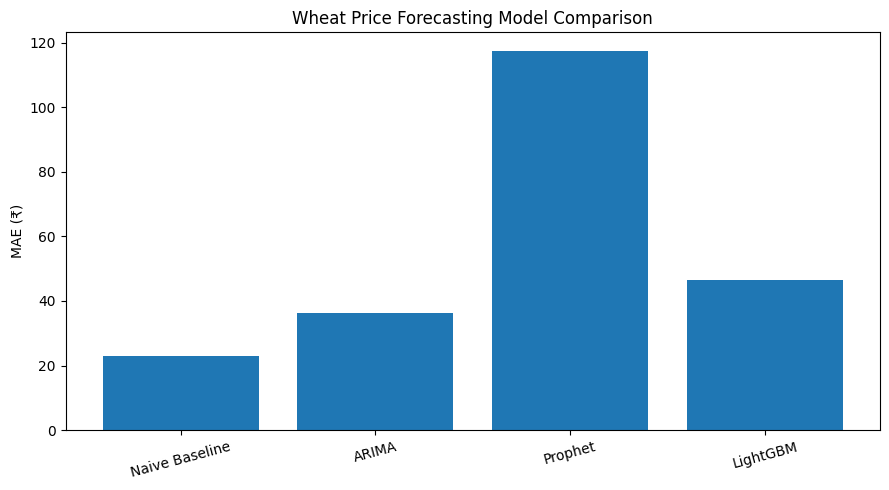

In [123]:
import matplotlib.pyplot as plt

models = [
    "Naive Baseline",
    "ARIMA",
    "Prophet",
    "LightGBM"
]

mae_values = [
    22.96,
    36.21,
    117.30,
    46.59
]

plt.figure(figsize=(9, 5))
plt.bar(models, mae_values)
plt.ylabel("MAE (₹)")
plt.title("Wheat Price Forecasting Model Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

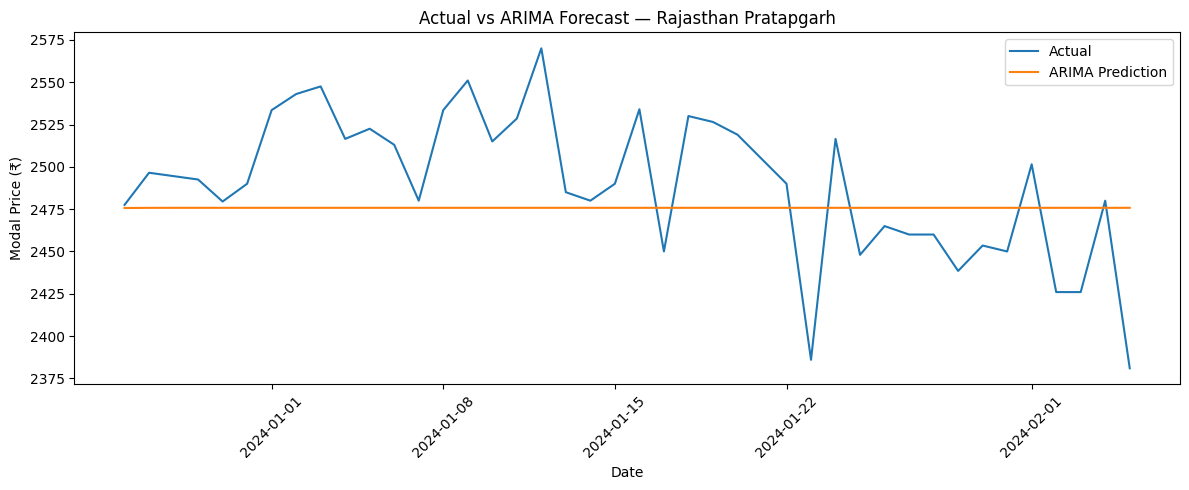

In [124]:
# Select one representative mandi
plot_market = "Pratapgarh"
plot_state = "Rajasthan"

plot_data = arima_results[
    (arima_results["STATE"] == plot_state) &
    (arima_results["Market Name"] == plot_market)
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    plot_data["Price Date"],
    plot_data["Actual"],
    label="Actual"
)

plt.plot(
    plot_data["Price Date"],
    plot_data["Predicted"],
    label="ARIMA Prediction"
)

plt.xlabel("Date")
plt.ylabel("Modal Price (₹)")
plt.title(
    f"Actual vs ARIMA Forecast — "
    f"{plot_state} {plot_market}"
)

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

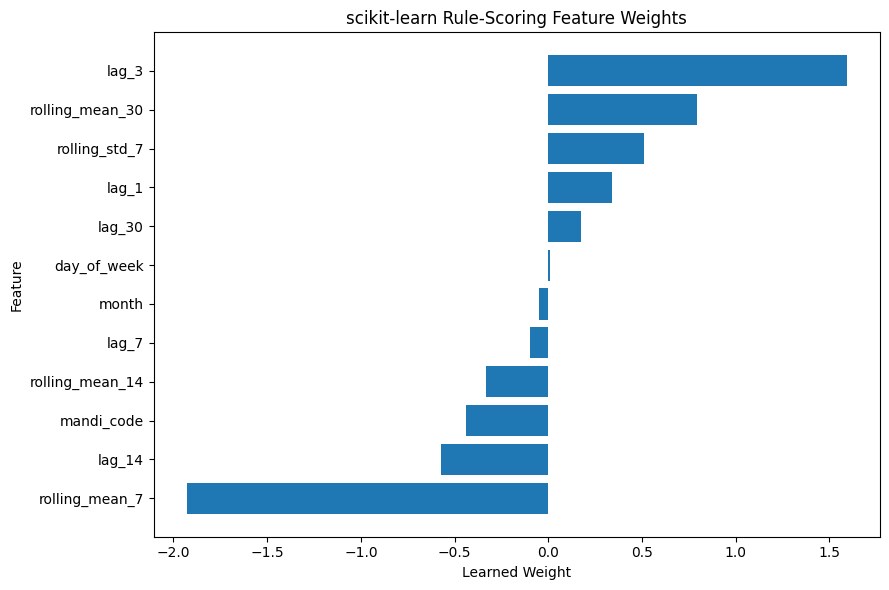

In [125]:
weights = pd.DataFrame({
    "Feature": score_features,
    "Weight": score_model.coef_[0]
})

weights = weights.sort_values(
    "Weight",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    weights["Feature"],
    weights["Weight"]
)

plt.xlabel("Learned Weight")
plt.ylabel("Feature")
plt.title(
    "scikit-learn Rule-Scoring Feature Weights"
)

plt.tight_layout()
plt.show()

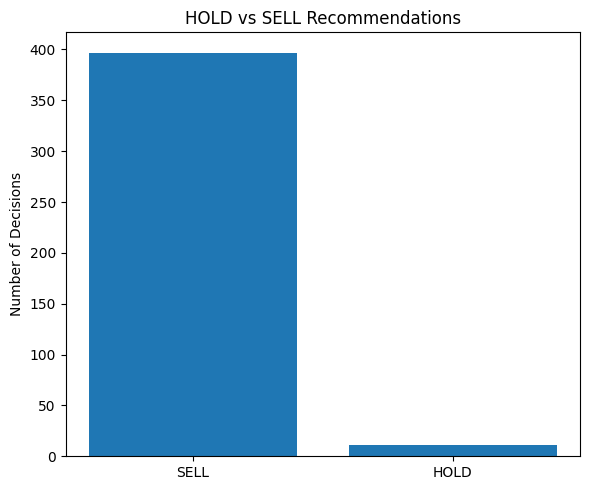

In [126]:
decision_counts = (
    final_strategy["Decision"]
    .value_counts()
)

plt.figure(figsize=(6, 5))

plt.bar(
    decision_counts.index,
    decision_counts.values
)

plt.ylabel("Number of Decisions")
plt.title("HOLD vs SELL Recommendations")
plt.tight_layout()
plt.show()